In [1]:
# =============================================
#                   IMPORT
# =============================================
from    preProcessingData                  import PreProcessData
from    utility.matpilotDraw               import MatPlot 
from    utility.plotlyDraw                 import PlotlyDraw
from    tqdm                               import tqdm
from    datetime                           import datetime
from    prettytable                        import PrettyTable
import  plotly.graph_objects                as go
import  numpy                               as np 
import  pandas                              as pd
import  matplotlib.pyplot                   as plt
import  os, warnings
import  random
import  json

np.random.seed(1)
random.seed(1)

# ====================================
# Config
# ------------------------------------
with open('utility/modelConfig.json', 'r') as configFile:
    config = json.load(configFile)
myConfig   = config["system"]



In [2]:
matPlot    = MatPlot() 
plotly     = PlotlyDraw()
preData    = PreProcessData()

In [3]:
cr1, cr2, cv2                           = preData.loadH5File(name = "criticalAllData", keys = ["cr1", "cr2", "cv2"])                           # Load the data from critical file

withIDCr1, withIDCr2, withIDCv2, IdSys  = preData.attachIDPerEvent(df = [cr1,cr2,cv2])



Process:47242||2024-11-19 16:04:34,112-INFO [preProcessingData.py:loadH5File():458]:Loading H5 file ...


Process:47242||2024-11-19 16:04:35,212-INFO [preProcessingData.py:loadH5File():464]:Finish loading data from files ...


In [4]:
# -----------------------------
# Normalize
normalizedCr1           = preData.normalizeBuilinFunction(withIDCr1, headline = preData.crusher1Value)  
normalizedCr2           = preData.normalizeBuilinFunction(withIDCr2, headline = preData.crusher2Value)  
normalizedCv2           = preData.normalizeBuilinFunction(withIDCv2, headline = preData.conveyorValue)  

# -----------------------------
# Add the Cycle and RUL to 
# each component
withTimeDataCr1         = preData.addCycleAndRul(normalizedCr1)                        # Add the time to the data
withTimeDataCr2         = preData.addCycleAndRul(normalizedCr2)                        # Add the time to the data
withTimeDataCv2         = preData.addCycleAndRul(normalizedCv2)                        # Add the time to the data

# -----------------------------
# Add the cycle and RUL of system
systemData                  = pd.DataFrame()
systemData['tiempo']        = withTimeDataCr1["tiempo"]
systemData['trajectoryID']  = IdSys
withTimeDataSys             = preData.addCycleAndRul(systemData)

Process:47242||2024-11-19 16:04:59,869-INFO [preProcessingData.py:normalizeBuilinFunction():1310]:Normalizing the data ....
Process:47242||2024-11-19 16:05:00,395-INFO [preProcessingData.py:normalizeBuilinFunction():1310]:Normalizing the data ....
Process:47242||2024-11-19 16:05:00,858-INFO [preProcessingData.py:normalizeBuilinFunction():1310]:Normalizing the data ....


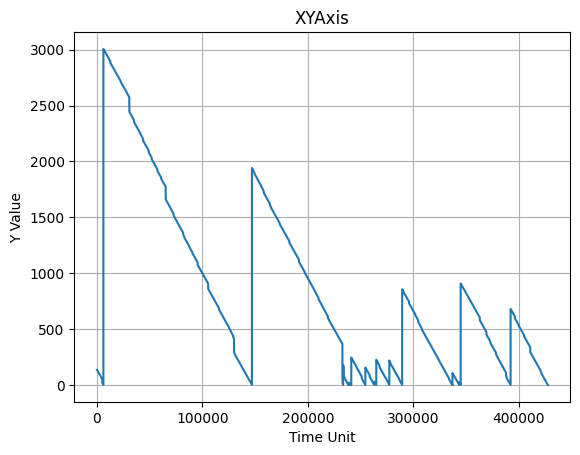

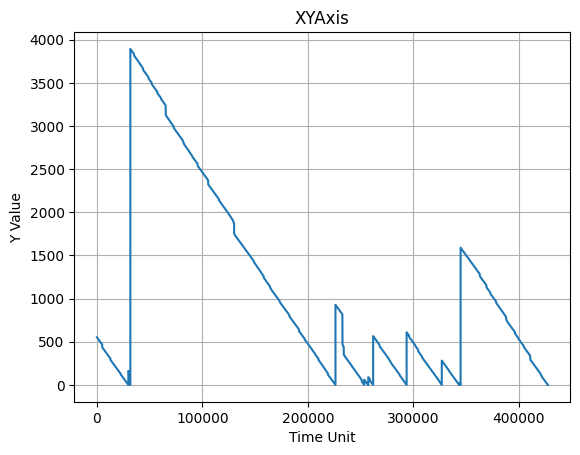

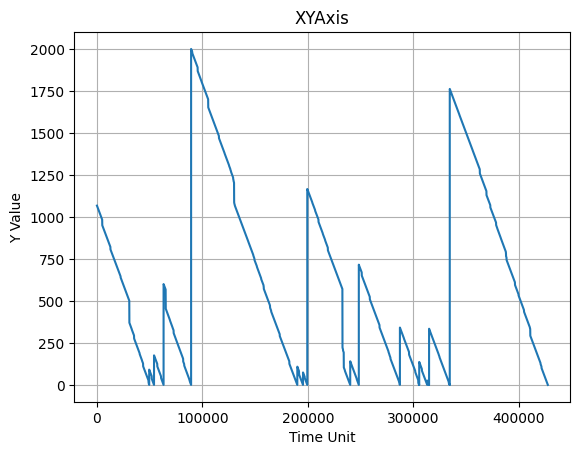

In [13]:
matPlot.draw1D(withTimeDataCr1["rul"])
matPlot.draw1D(withTimeDataCr2["rul"])
matPlot.draw1D(withTimeDataCv2["rul"])


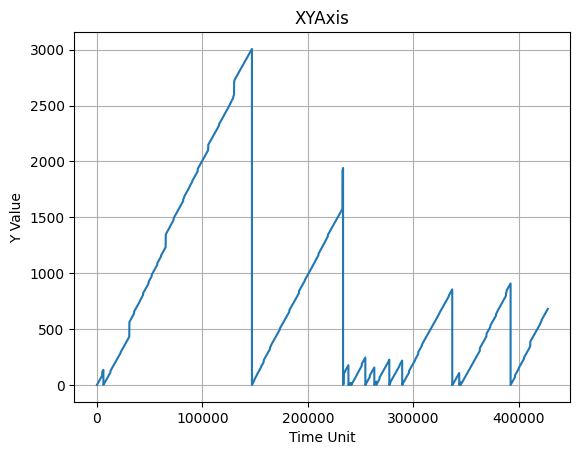

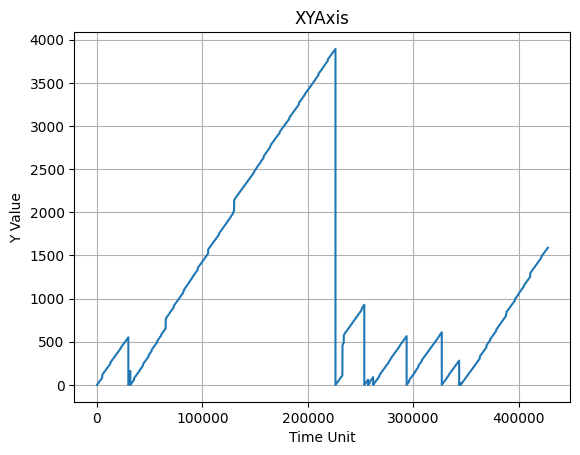

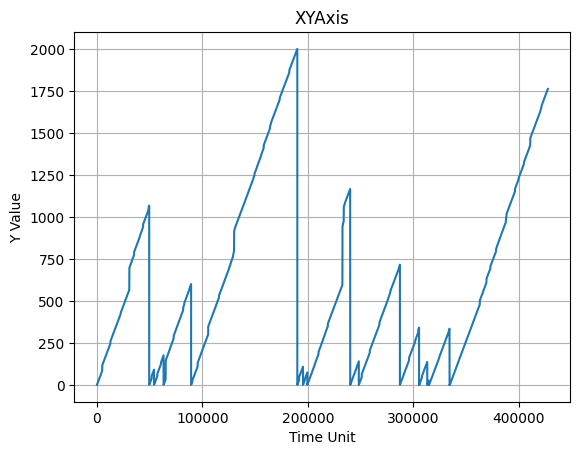

In [14]:
matPlot.draw1D(withTimeDataCr1["cycle"])
matPlot.draw1D(withTimeDataCr2["cycle"])
matPlot.draw1D(withTimeDataCv2["cycle"])

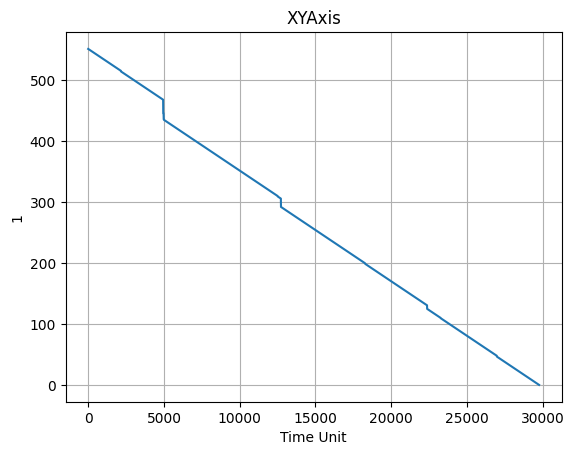

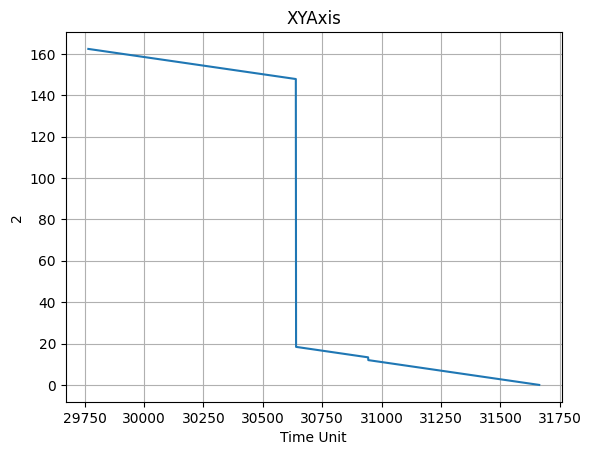

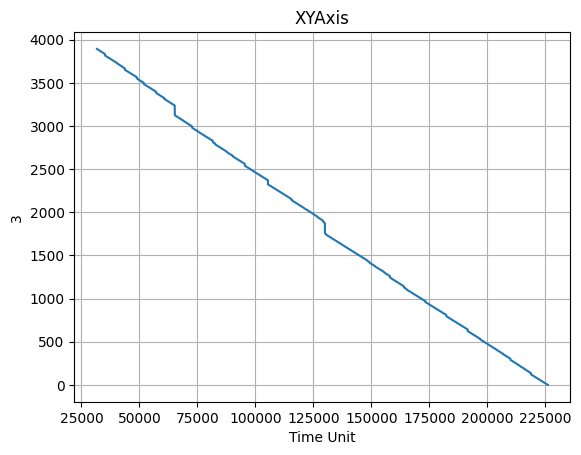

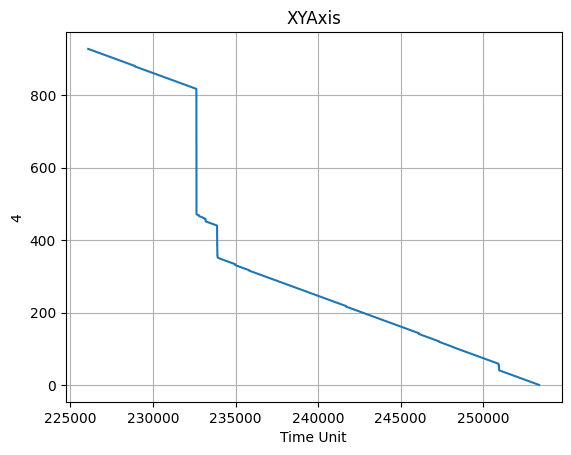

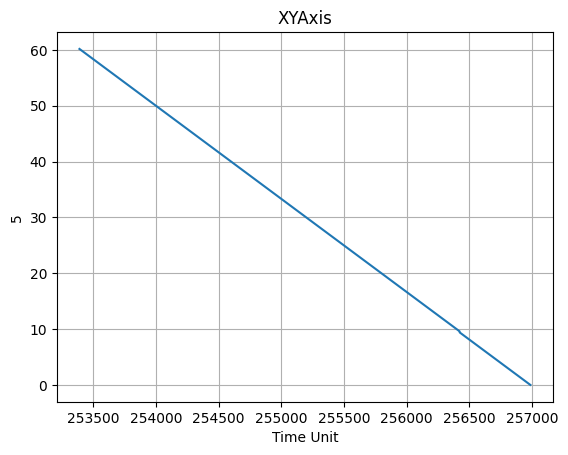

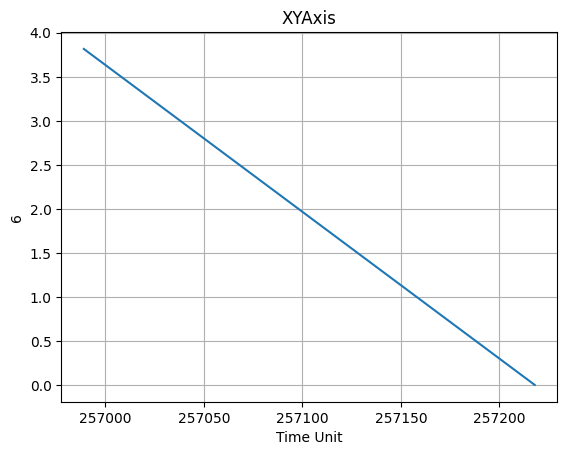

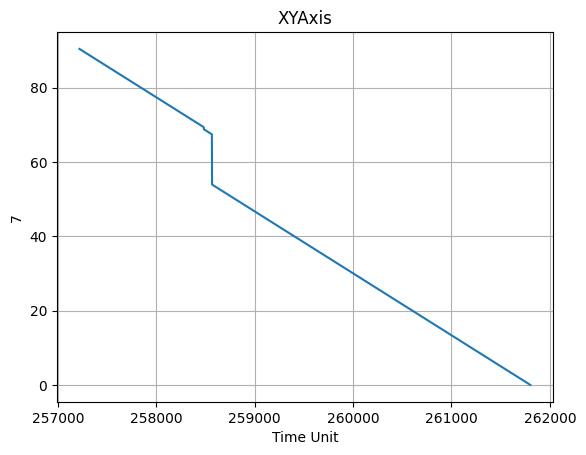

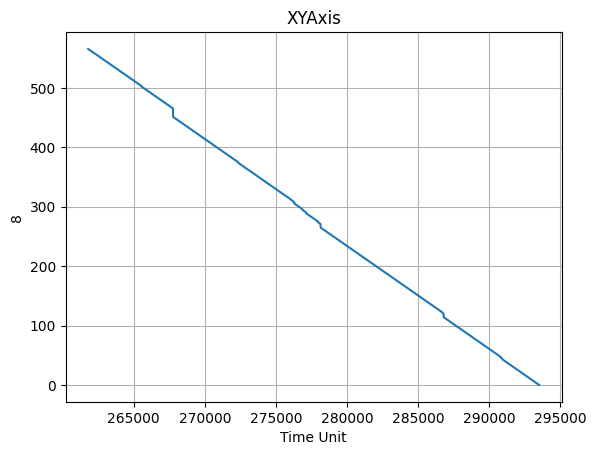

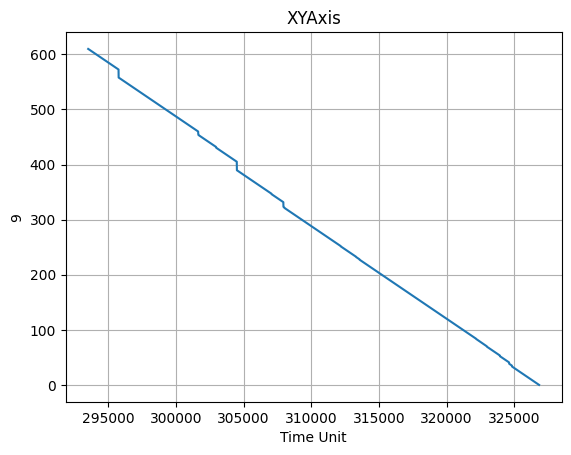

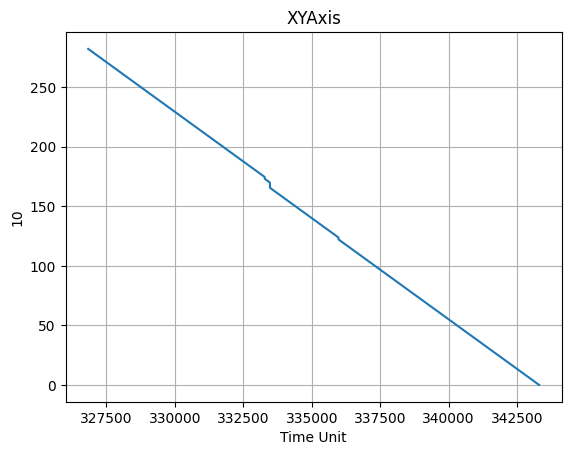

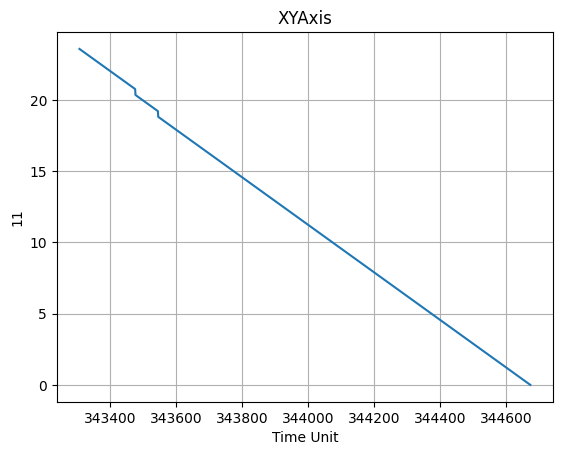

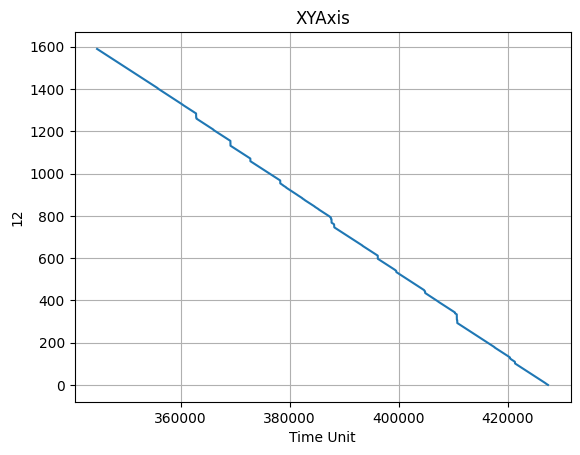

In [10]:
for idx in range(withIDCr2["trajectoryID"].values.max()):
    data = withTimeDataCr2["rul"][withTimeDataCr2["trajectoryID"] == (idx + 1)]
    matPlot.draw1D(data, yLabel= (idx + 1))